In [2]:
import pandas as pd
import numpy as np

In [3]:
import pandas as pd
import numpy as np

# Load metadata
df_meta = pd.read_excel('data/raw/Supplementary Table S1.xlsx', header=3)
df_meta.rename(columns={
    df_meta.columns[0]: 'Sample id'
}, inplace=True)

def clean_metadata(df):
    # 1. Create Depression Label
    # ICD-10 F32/F33 = Depressive episodes. Healthy = 0.
    df['Depression'] = df['Diagnosis'].apply(lambda x: 1 if 'F3' in str(x) else 0)
    
    # 2. Create Anxiety Label (GAD-7 > 10 is moderate-to-severe anxiety)
    # Use >= 7 to capture the top 40% of anxiety scores in this dataset
    df['Anxiety'] = df['GAD-7'].apply(lambda x: 1 if x >= 7 else 0)
    
    # 3. Clean Metadata Features
    # Convert Sex to binary: Male=0, Female=1
    df['Sex'] = df['Sex'].map({'Male': 0, 'Female': 1})
    
    # Handle BMI: Replace missing (-) with the median
    df['BMI, kg/m2'] = pd.to_numeric(df['BMI, kg/m2'], errors='coerce')
    df['BMI, kg/m2'] = df['BMI, kg/m2'].fillna(df['BMI, kg/m2'].median())
    
    # Keep only target and selected features
    cols_to_keep = ['Sample id', 'Age, y.o.', 'Sex', 'BMI, kg/m2', 'Depression', 'Anxiety']
    return df[cols_to_keep]

df_meta_cleaned = clean_metadata(df_meta)
df_meta_cleaned.to_csv('data/processed/labels_metadata.csv', index=False)
print("Phase 1 Complete: Labels decoded.")

Phase 1 Complete: Labels decoded.


In [4]:
# Load Genus table (S4b)
# Note: In S4b, Genuses are rows and Samples are columns. We need to transpose.
df_genus = pd.read_excel(
    "data/raw/Supplementary Table S4.xlsx",
    sheet_name=1,      # 2nd sheet (0-based index)
    header=1,          # row where HC_1, HC_2... starts
    index_col=0
).T

df_genus.head()

# Merge with Metadata
print(f"Metadata rows: {len(df_meta)}")
print(f"Abundance rows: {len(df_genus)}")
df_final = df_meta_cleaned.merge(df_genus, left_on='Sample id', right_index=True)
print(f"Final merged rows: {len(df_final)}") # This should be ~74

# 1. Rare Taxa Filtering (Keep genera present in >10% of samples)
genus_cols = df_genus.columns
presence_mask = (df_final[genus_cols] > 0).mean() > 0.10
selected_genera = genus_cols[presence_mask]

# 2. CLR Transformation
def clr_transform(data):
    # Add a small pseudocount (1e-6) because log(0) is undefined
    data = data + 1e-6
    log_data = np.log(data)
    # Subtract the geometric mean
    return log_data.sub(log_data.mean(axis=1), axis=0)

df_features = clr_transform(df_final[selected_genera])
# Combine with metadata features (Age, Sex, BMI)
X = pd.concat([df_final[['Age, y.o.', 'Sex', 'BMI, kg/m2']], df_features], axis=1)
Y = df_final[['Depression', 'Anxiety']]

X.to_csv('data/processed/features_X.csv', index=False)
Y.to_csv('data/processed/targets_Y.csv', index=False)


Metadata rows: 74
Abundance rows: 79
Final merged rows: 74


In [5]:
from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import MultiTaskElasticNetCV

# 1. THE ROUGH CUT: Boruta (Targeting the whole Y matrix)
# Since Boruta takes one vector, we create a "Combined" target 
# to ensure we don't miss features relevant to EITHER condition.
y_combined = Y.max(axis=1) # 1 if they have Depression OR Anxiety

rf = RandomForestClassifier(n_jobs=-1, class_weight='balanced', max_depth=5)
boruta_selector = BorutaPy(rf, n_estimators='auto', random_state=42)
boruta_selector.fit(X.values, y_combined.values)

# Features that passed the first "Rough" filter
X_boruta = X.iloc[:, boruta_selector.support_]
print(f"Boruta selected {X_boruta.shape[1]} features.")

# 2. THE PRECISION CUT: Multi-Task Elastic Net
# This is the "Elastic Net" part you were looking for. 
# It finds features that predict both Depression and Anxiety at the same time.
# MultiTaskElasticNetCV automatically finds the best 'alpha' (strength of selection).

mt_en = MultiTaskElasticNetCV(cv=5, random_state=42, selection='random')
mt_en.fit(X_boruta, Y)

# Get the names of features that have a non-zero weight for either task
# If the weight is 0, Elastic Net has 'deleted' that feature.
mten_support = np.sum(np.abs(mt_en.coef_), axis=0) > 0
final_features = X_boruta.columns[mten_support]

X = X[final_features]
print(f"Elastic Net refined this to {len(final_features)} features.")
print("Final Selected Microbiome Markers:", final_features.tolist())


Boruta selected 17 features.
Elastic Net refined this to 13 features.
Final Selected Microbiome Markers: ['Lachnospira', 'Ruthenibacterium', 'Veillonella', 'Gardnerella', 'Pseudobutyrivibrio', 'Kocuria', 'Trueperella', 'Lancefieldella', 'Fructilactobacillus', 'Lachnoanaerobaculum', 'Corynebacterium', 'Raoultella', 'Lawsonella']


In [23]:
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

y_str = Y.apply(lambda x: f"{int(x['Depression'])}_{int(x['Anxiety'])}", axis=1)

# 1. Identify classes with too few samples
counts = y_str.value_counts()
# Keep only classes that have at least 2 samples so a neighbor can be found
valid_classes = counts[counts >= 2].index
mask = y_str.isin(valid_classes)

X_filtered = X[mask]
y_filtered_str = y_str[mask]

# 2. Configure SMOTE with lower k_neighbors
# We set k_neighbors to the minimum possible (1) to accommodate tiny groups
smote_logic = SMOTE(random_state=42, k_neighbors=1)

# 3. Apply SMOTE-Tomek with the custom SMOTE logic
smt = SMOTETomek(random_state=42, smote=smote_logic)

X_resampled, y_resampled_str = smt.fit_resample(X_filtered, y_filtered_str)

print(f"Original: {len(X)} | Filtered: {len(X_filtered)} | Resampled: {len(X_resampled)}")

y_resampled = np.array([
    list(map(int, label.split('_')))
    for label in y_resampled_str
])

print(y_resampled.shape)
print(y_resampled)

Original: 74 | Filtered: 73 | Resampled: 111
(111, 2)
[[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]]


In [9]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sklearn.model_selection import cross_val_score

# Use 5-Fold CV to get a 'Real' average score
mksf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [100]:
import shap

In [123]:

# Phase 4: Baseline Multilabel Model (Random Forest)
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, multilabel_confusion_matrix
from skmultilearn.model_selection import iterative_train_test_split

# 2. Initialize Multi-Output Random Forest
# We use balanced class weights because mental health datasets are often imbalanced
base_rf = RandomForestClassifier(
    n_estimators=200, 
    class_weight='balanced_subsample', # KEY CHANGE
    max_depth=10, 
    random_state=42)

multi_rf = MultiOutputClassifier(base_rf)

# 3. Train
depression_auc_scores = []
anxiety_auc_scores = []

all_y_true = []
all_y_pred = []

# Lists to store shap results from every fold
all_shap_dep = []
all_shap_anx = []
all_features = []

for fold, (train_index, test_index) in enumerate(mksf.split(X_resampled, y_resampled)):
    X_train_cv, X_test_cv = X_resampled.iloc[train_index], X_resampled.iloc[test_index]
    y_train_cv, y_test_cv = y_resampled[train_index], y_resampled[test_index]

    multi_rf.fit(X_train_cv, y_train_cv)
    y_pred = multi_rf.predict(X_test_cv)
    probs = multi_rf.predict_proba(X_test_cv)
    
    print("feature importance depression", multi_rf.estimators_[0].feature_importances_)
    print("feature importance anxiety", multi_rf.estimators_[1].feature_importances_)

# Extract positive class probabilities
    if probs[0].shape[1] > 1:
        depression_prob = probs[0][:, 1]
    else:
        depression_prob = np.zeros(len(probs[0]))

# Anxiety
    if probs[1].shape[1] > 1:
        anxiety_prob = probs[1][:, 1]
    else:
        anxiety_prob = np.zeros(len(probs[1]))

    # Depression AUC
    if len(np.unique(y_test_cv[:, 0])) > 1:
        dep_auc = roc_auc_score(y_test_cv[:, 0], depression_prob)
        depression_auc_scores.append(dep_auc)
        print(f"Depression AUC: {dep_auc:.3f}")

    if len(np.unique(y_test_cv[:, 1])) > 1:
        anx_auc = roc_auc_score(y_test_cv[:, 1], anxiety_prob)
        anxiety_auc_scores.append(anx_auc)
        print(f"Anxiety AUC: {anx_auc:.3f}")

    # Store for overall classification report
    all_y_true.append(y_test_cv)
    all_y_pred.append(y_pred)
    
    # Calculate SHAP for Depression (Index 0)
    explainer_dep = shap.TreeExplainer(multi_rf.estimators_[0])
    shap_dep = explainer_dep.shap_values(X_test_cv)
    
    
    print(f"Max SHAP value depression: {np.max(np.abs(shap_dep))}")
    # Handle the list/array output logic (same as your previous function)
    all_shap_dep.append(shap_dep[1] if isinstance(shap_dep, list) else shap_dep)

    # Calculate SHAP for Anxiety (Index 1)
    explainer_anx = shap.TreeExplainer(multi_rf.estimators_[1])
    shap_anx = explainer_anx.shap_values(X_test_cv)

    print(f"Max SHAP value anxiety: {np.max(np.abs(shap_anx))}")
    all_shap_anx.append(shap_anx[1] if isinstance(shap_anx, list) else shap_anx)

    # Store the features used in this fold
    all_features.append(X_test_cv)

# Combine all folds
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

# Final Classification Report
print("\n=== Final Multilabel Classification Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

# Final AUC summary
print("\n=== AUC Summary ===")
print(f"Mean Depression AUC: {np.mean(depression_auc_scores):.3f}")
print(f"Mean Anxiety AUC: {np.mean(anxiety_auc_scores):.3f}")

feature importance depression [0.11396334 0.10005673 0.12700096 0.05579402 0.09412196 0.04423289
 0.06482407 0.07018631 0.08114618 0.08387816 0.05785194 0.03918284
 0.06776061]
feature importance anxiety [0.04415306 0.06219079 0.06573263 0.05546021 0.0556467  0.04184195
 0.09890977 0.17933607 0.07156951 0.05562136 0.1337864  0.09889667
 0.03685487]
Depression AUC: 0.955
Anxiety AUC: 0.990
Max SHAP value depression: 0.1621283378766694
Max SHAP value anxiety: 0.20396071538712773
feature importance depression [0.1379742  0.14492152 0.10912131 0.06235442 0.07582672 0.07712038
 0.05825591 0.0487476  0.06519774 0.07479606 0.03571585 0.05536744
 0.05460085]
feature importance anxiety [0.03813545 0.06540224 0.07548249 0.0495104  0.05042204 0.04740907
 0.09128806 0.12688531 0.0799699  0.04190239 0.16451862 0.12756313
 0.0415109 ]
Depression AUC: 0.943
Anxiety AUC: 0.915
Max SHAP value depression: 0.13858589027670037
Max SHAP value anxiety: 0.20350975384476316
feature importance depression [0.14


=== Global SHAP Summary: Depression (All Folds Combined) ===


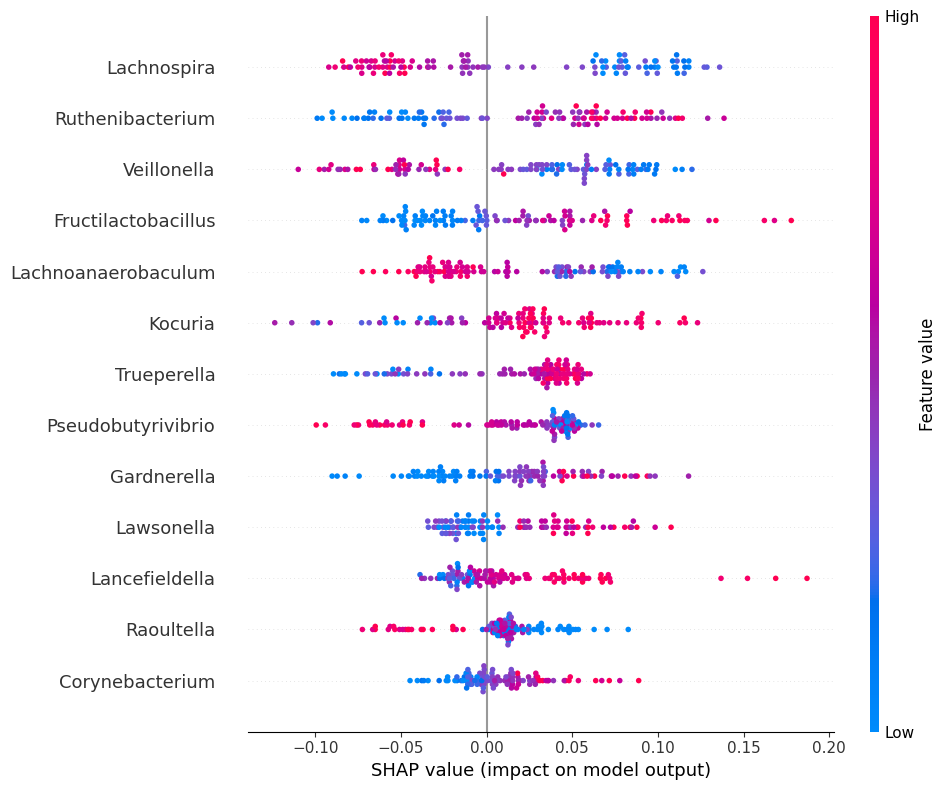


=== Global SHAP Summary: Anxiety (All Folds Combined) ===


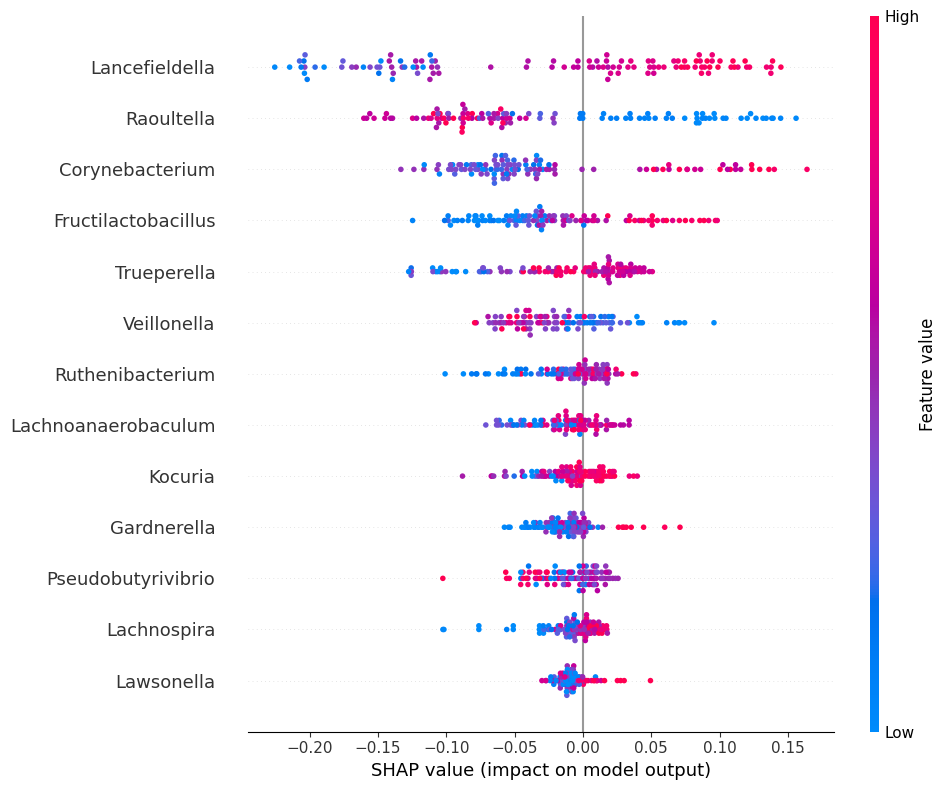

In [125]:
import matplotlib.pyplot as plt

plt.close('all')

# Combine everything
final_shap_dep = np.vstack(all_shap_dep)
final_shap_anx = np.vstack(all_shap_anx)
final_features = pd.concat(all_features)

# Now plot the Global Summary

print("\n=== Global SHAP Summary: Depression (All Folds Combined) ===")
shap_dep_main = final_shap_dep[:,:,1]

shap.summary_plot(shap_dep_main, final_features,
                  plot_type="dot", max_display=20, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 8)
fig.tight_layout()
plt.show()

shap_anx_main = final_shap_anx[:, :, 1]
print("\n=== Global SHAP Summary: Anxiety (All Folds Combined) ===")
shap.summary_plot(shap_anx_main, final_features, plot_type="dot", max_display=20, show=False)
fig_anx = plt.gcf()
fig_anx.set_size_inches(10, 8)
fig_anx.tight_layout()
plt.show()

In [126]:
# Updated build function to RETURN values instead of just plotting
def get_shap_values_xgb(target_idx, best_model, X_test_cv, y_test_cv):
    # Select the specific model for the label in the chain
    chain_model = best_model.estimators_[target_idx]
    
    if target_idx == 1:
        # For Anxiety: features + Depression prediction
        # We use the actual labels from y_test_cv for the "context" during explanation
        X_context = np.hstack([X_test_cv.values, y_test_cv[:, [0]]])
        feature_names = list(X_test_cv.columns) + ['Depression_Context']
    else:
        # For Depression: just features
        X_context = X_test_cv.values
        feature_names = list(X_test_cv.columns)

    explainer = shap.TreeExplainer(chain_model)
    shap_values = explainer.shap_values(X_context, check_additivity=False)

    # Standardize output: Binary XGBoost often returns (samples, features)
    if isinstance(shap_values, list):
        shap_to_store = shap_values[1]
    else:
        shap_to_store = shap_values
        
    return shap_to_store, X_context, feature_names

In [127]:
from sklearn.multioutput import ClassifierChain
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score, hamming_loss, accuracy_score, f1_score

# 1. Define the Base XGBoost inside the Chain
# We use order=[0, 1] to ensure Depression helps predict Anxiety
base_xgb = XGBClassifier(eval_metric='logloss', random_state=42)

chain = ClassifierChain(estimator=base_xgb, order=[0, 1])

# 2. Define Parameters for Tuning (Note the 'base_estimator__' prefix for Chains)
param_grid = {
    'estimator__n_estimators': [50, 100],
    'estimator__max_depth': [3, 5, 7],
    'estimator__learning_rate': [0.1]
}

depression_auc_scores = []
anxiety_auc_scores = []

all_y_true = []
all_y_pred = []

all_shap_dep = []
all_shap_anx = []
all_features = []

for fold, (train_index, test_index) in enumerate(mksf.split(X_resampled, y_resampled), 1):
    print(f"\n--- Fold {fold} ---")

    X_train_cv, X_test_cv = X_resampled.iloc[train_index], X_resampled.iloc[test_index]
    y_train_cv, y_test_cv = y_resampled[train_index], y_resampled[test_index]
    
    # Use a stratified inner CV to prevent "Single Class" errors
    inner_cv = MultilabelStratifiedKFold(n_splits=2, shuffle=True, random_state=42)

    # GridSearch inside each fold
    grid_search = GridSearchCV(
        estimator=chain,
        param_grid=param_grid,
        cv=inner_cv,
        scoring='f1_macro',
        n_jobs=-1,
        error_score=0
    )

    grid_search.fit(X_train_cv, y_train_cv)

    best_model = grid_search.best_estimator_
    print("Best Params:", grid_search.best_params_)

    # Predictions
    y_pred = best_model.predict(X_test_cv)
    y_prob = best_model.predict_proba(X_test_cv)

    depression_prob = y_prob[:, 0]
    anxiety_prob = y_prob[:, 1]

    # Depression AUC
    if len(np.unique(y_test_cv[:, 0])) > 1:
        dep_auc = roc_auc_score(y_test_cv[:, 0], depression_prob)
        depression_auc_scores.append(dep_auc)
        print(f"Depression AUC: {dep_auc:.3f}")
    else:
        print("Depression AUC skipped: only one class present")

    # Anxiety AUC
    if len(np.unique(y_test_cv[:, 1])) > 1:
        anx_auc = roc_auc_score(y_test_cv[:, 1], anxiety_prob)
        anxiety_auc_scores.append(anx_auc)
        print(f"Anxiety AUC: {anx_auc:.3f}")
    else:
        print("Anxiety AUC skipped: only one class present")

    all_y_true.append(y_test_cv)
    all_y_pred.append(y_pred)
    
    s_dep, x_dep, f_dep = get_shap_values_xgb(0, best_model, X_test_cv, y_test_cv)
    all_shap_dep.append(s_dep)
    # We only need to store the raw features for the base model
    all_features.append(X_test_cv) 

    # Store Anxiety SHAP
    s_anx, x_anx, f_anx = get_shap_values_xgb(1, best_model, X_test_cv, y_test_cv)
    all_shap_anx.append(s_anx)
    # Important: Anxiety needs its own feature context list because it has +1 column
    # Let's create a separate list for anxiety features
    if fold == 1: all_features_anx = []
    all_features_anx.append(pd.DataFrame(x_anx, columns=f_anx))
    
    
# Combine all folds
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

print("\n=== Final XGBoost Chain Multilabel Classification Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

print("\n=== XGBoost Chain AUC Summary ===")

print(f"Mean Depression AUC: {np.mean(depression_auc_scores):.3f}")
print(f"Mean Anxiety AUC: {np.mean(anxiety_auc_scores):.3f}")

print("\n=== Other Multilabel Metrics ===")

print(f"Hamming Loss: {hamming_loss(all_y_true, all_y_pred):.3f}")
print(f"Exact Match Accuracy: {accuracy_score(all_y_true, all_y_pred):.3f}")
print(f"F1 Micro: {f1_score(all_y_true, all_y_pred, average='micro', zero_division=0):.3f}")
print(f"F1 Macro: {f1_score(all_y_true, all_y_pred, average='macro', zero_division=0):.3f}")


--- Fold 1 ---
Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 50}
Depression AUC: 0.991
Anxiety AUC: 0.962

--- Fold 2 ---
Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 50}
Depression AUC: 0.924
Anxiety AUC: 0.804

--- Fold 3 ---
Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 50}
Depression AUC: 0.917
Anxiety AUC: 0.808

--- Fold 4 ---
Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.952
Anxiety AUC: 0.905

--- Fold 5 ---
Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 5, 'estimator__n_estimators': 50}
Depression AUC: 0.971
Anxiety AUC: 0.867

=== Final XGBoost Chain Multilabel Classification Report ===

              precision    recall  f1-score   support

  Depression       0.87      0.91      0.89        74
     Anxiety     


=== Global SHAP: Depression ===


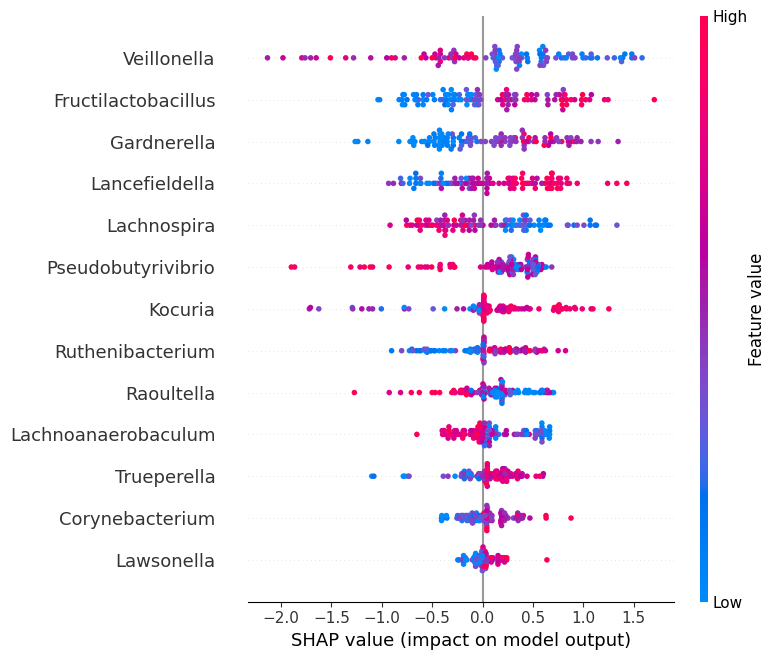


=== Global SHAP: Anxiety (with Depression Context) ===


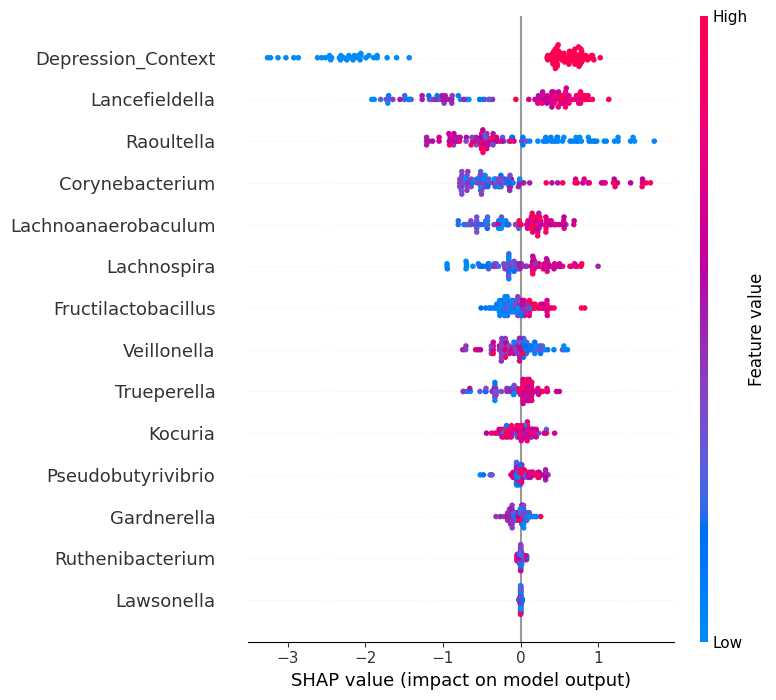

In [128]:
# 1. Aggregate Depression (Standard Features)
final_shap_dep = np.vstack(all_shap_dep)
final_features_dep = pd.concat(all_features)

print("\n=== Global SHAP: Depression ===")
shap.summary_plot(final_shap_dep, final_features_dep, plot_type="dot")

# 2. Aggregate Anxiety (Standard Features + Depression Context)
final_shap_anx = np.vstack(all_shap_anx)
final_features_anx = pd.concat(all_features_anx)

print("\n=== Global SHAP: Anxiety (with Depression Context) ===")
shap.summary_plot(final_shap_anx, final_features_anx, plot_type="dot")

In [ ]:
#Phase 5: Advanced Model (XGBoost with Hyperparameter Tuning)
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    hamming_loss,
    accuracy_score,
    f1_score
)

# 1. Setup Multi-Output XGBoost
xgb = MultiOutputClassifier(XGBClassifier(use_label_encoder=False, eval_metric='logloss'))

# 2. Define Parameters for Tuning
param_grid = {
    'estimator__n_estimators': [50, 100],
    'estimator__max_depth': [3, 5, 7],
    'estimator__learning_rate': [0.01, 0.1]
}

# 3. Grid Search with 5-Fold Cross-Validation
depression_auc_scores = []
anxiety_auc_scores = []

all_y_true = []
all_y_pred = []

# Define this outside the loop
inner_cv = MultilabelStratifiedKFold(n_splits=2, shuffle=True, random_state=42)

for fold, (train_index, test_index) in enumerate(mksf.split(X_resampled, y_resampled), 1):
    print(f"\n--- Fold {fold} ---")

    X_train_cv, X_test_cv = X_resampled.iloc[train_index], X_resampled.iloc[test_index]
    y_train_cv, y_test_cv = y_resampled[train_index], y_resampled[test_index]

    # GridSearch inside each fold
    grid_search = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        cv=inner_cv,
        scoring='f1_macro',
        n_jobs=-1,
        error_score=0
    )

    grid_search.fit(X_train_cv, y_train_cv)

    best_model = grid_search.best_estimator_
    print("Best Params:", grid_search.best_params_)

    # Predictions
    y_pred = best_model.predict(X_test_cv)
    y_prob = best_model.predict_proba(X_test_cv)

    depression_prob = y_prob[0][:, 0]
    anxiety_prob = y_prob[1][:, 1]

    # Depression AUC
    if len(np.unique(y_test_cv[:, 0])) > 1:
        dep_auc = roc_auc_score(y_test_cv[:, 0], depression_prob)
        depression_auc_scores.append(dep_auc)
        print(f"Depression AUC: {dep_auc:.3f}")
    else:
        print("Depression AUC skipped: only one class present")

    # Anxiety AUC
    if len(np.unique(y_test_cv[:, 1])) > 1:
        anx_auc = roc_auc_score(y_test_cv[:, 1], anxiety_prob)
        anxiety_auc_scores.append(anx_auc)
        print(f"Anxiety AUC: {anx_auc:.3f}")
    else:
        print("Anxiety AUC skipped: only one class present")

    all_y_true.append(y_test_cv)
    all_y_pred.append(y_pred)
    
    grid_search.fit(X_train_cv, y_train_cv)
    best_model = grid_search.best_estimator_

    

# Combine all folds
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

print("\n=== Final XGBoost Multilabel Classification Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

print("\n=== XGBoost AUC Summary ===")

print(f"Mean Depression AUC: {np.mean(depression_auc_scores):.3f}")
print(f"Mean Anxiety AUC: {np.mean(anxiety_auc_scores):.3f}")

print("\n=== Other Multilabel Metrics ===")

print(f"Hamming Loss: {hamming_loss(all_y_true, all_y_pred):.3f}")
print(f"Exact Match Accuracy: {accuracy_score(all_y_true, all_y_pred):.3f}")
print(f"F1 Micro: {f1_score(all_y_true, all_y_pred, average='micro', zero_division=0):.3f}")
print(f"F1 Macro: {f1_score(all_y_true, all_y_pred, average='macro', zero_division=0):.3f}")


--- Fold 1 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 50}
Depression AUC: 0.009
Anxiety AUC: 0.943

--- Fold 2 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 5, 'estimator__n_estimators': 50}
Depression AUC: 0.095
Anxiety AUC: 0.821

--- Fold 3 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.083
Anxiety AUC: 0.883

--- Fold 4 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'estimator__learning_rate': 0.01, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}
Depression AUC: 0.095
Anxiety AUC: 0.981

--- Fold 5 ---
Best Params: {'estimator__learning_rate': 0.1, 'estimator__max_depth': 3, 'estimator__n_estimators': 50}
Depression AUC: 0.048
Anxiety AUC: 0.943

=== Final XGBoost Multilabel Classification Report ===

              precision    recall  f1-score   support

  Depression       0.89      0.89      0.89        74
     Anxiety       0.83      0.81      0.82        37

   micro avg       0.87      0.86      0.87       111
   macro avg       0.86      0.85      0.86       111
weighted avg       0.87      0.86      0.87       111
 samples avg       0.60      0.59      0.59       111


=== XGBoost AUC Summary ===
Mean Depression AUC: 0.066
Mean Anxiety AUC: 0.914

=== Other Multilabel Metrics ===
Hamming Loss: 0.131
Exact Match Accuracy: 0.811
F1 Micro: 0.869
F1 Macro: 0.857


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:53:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [31]:
#Phase 6: Angelova-style Image Generation (Updated for Selected Features)
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers, models, regularizers

# Create folder
os.makedirs('plots/heatmaps', exist_ok=True)

def create_microbiome_images(X_data, folder='plots/heatmaps'):
    # Determine grid size based on the number of features selected in Phase 3
    num_features = X_data.shape[1]
    grid_size = int(np.ceil(np.sqrt(num_features)))
    
    for i in range(len(X_data)):
        # 1. Extract sample and normalize to 0-1 for visualization
        sample_vec = X_data.iloc[i].values
        norm_vec = (sample_vec - sample_vec.min()) / (sample_vec.max() - sample_vec.min() + 1e-6)
        
        # 2. Pad with zeros to make it a perfect square
        padded = np.pad(norm_vec, (0, grid_size**2 - num_features), mode='constant')
        img_grid = padded.reshape(grid_size, grid_size)
        
        # 3. Save as grayscale or viridis heatmap
        plt.imsave(f'{folder}/sample_{i}.png', img_grid, cmap='magma')

create_microbiome_images(X_resampled)

import tensorflow as tf
from tensorflow.keras import layers, models
import cv2

def load_images_as_data(image_folder, labels_df):
    images = []
    # Ensure images are loaded in the same order as labels
    for i in range(len(labels_df)):
        img_path = os.path.join(image_folder, f'sample_{i}.png')
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (64, 64)) # Resize for consistency
        images.append(img)
    return np.array(images).reshape(-1, 64, 64, 1) / 255.0

# 1. Prepare Data
X_img = load_images_as_data('plots/heatmaps', y_resampled)
y_img = y_resampled # Depression and Anxiety columns

In [144]:
def build_cnn_model():
    # Define the input explicitly
    inputs = layers.Input(shape=(64, 64, 1))
    
    # Layer 1
    x = layers.Conv2D(
        16, (3, 3),
        activation='relu',
        padding='same',
        kernel_regularizer=regularizers.l2(0.001)
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Layer 2 (Target for Grad-CAM)
    x = layers.Conv2D(
        32, (3, 3),
        activation='relu',
        padding='same',
        name="target_conv_layer",
        kernel_regularizer=regularizers.l2(0.001)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Output
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(2, activation='sigmoid')(x)

    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=Adam(learning_rate=1e-5), loss='binary_crossentropy', metrics=['accuracy'])

    return model

In [147]:
def get_gradcam_results(grad_model, img_array):
    """
    Args:
        grad_model: The functional model mapping input -> [conv_output, final_output]
        img_array: Single image batch (1, 64, 64, 1)
    """
    heatmaps = []
    
    # Cast once outside the loop
    img_tensor = tf.cast(img_array, tf.float32)

    for i in [0, 1]: # 0 for Depression, 1 for Anxiety
        with tf.GradientTape() as tape:
            # 1. Forward pass returns a list [conv_outputs, predictions]
            outputs = grad_model(img_tensor)
            
            # 2. Unpack the list correctly
            conv_outputs = outputs[0]
            predictions = outputs[1]
            
            # 3. Index the specific class prediction
            loss = predictions[:, i]

        # 4. Calculate gradients of the class score w.r.t. the conv layer output
        grads = tape.gradient(loss, conv_outputs)
        
        # 5. Global Average Pooling of the gradients (Aggregation)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

        # 6. Weight the convolutional output by the pooled gradients
        # Use only the first (and only) image in the batch
        conv_output_first = conv_outputs[0]
        heatmap = conv_output_first @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)

        # 7. Apply ReLU and Normalize
        heatmap = tf.maximum(heatmap, 0)
        max_val = tf.math.reduce_max(heatmap)
        if max_val != 0:
            heatmap = heatmap / max_val
            
        heatmaps.append(heatmap.numpy())
        
    return heatmaps

In [155]:
all_y_true = []
all_y_pred = []

fold_f1_scores = []
fold_hamming_losses = []

histories = []

auc_depression = []
auc_anxiety = []

global_heatmaps_dep = []
global_heatmaps_anx = []

for fold, (train_idx, val_idx) in enumerate(mksf.split(X_img, y_img), 1):
    print(f"\n--- CNN Fold {fold} ---")

    X_train_fold = X_img[train_idx]
    X_val_fold = X_img[val_idx]

    y_train_fold = y_img[train_idx]
    y_val_fold = y_img[val_idx]

    model = build_cnn_model()

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ModelCheckpoint('models/best_cnn_model.keras', monitor='val_loss', save_best_only=True)
    ]

    sample_weights = np.ones(len(y_train_fold))
    sample_weights[y_train_fold[:, 1] == 1] = 2.0

    history = model.fit(
        X_train_fold,
        y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=30,
        batch_size=4,
        sample_weight=sample_weights,
        callbacks=callbacks,
        verbose=0
    )
    
    histories.append(history)

    y_prob = model.predict(X_val_fold)
    y_pred = (y_prob >= 0.5).astype(int)
    
    y_val_dep = y_val_fold[:, 0]
    y_val_anx = y_val_fold[:, 1]
    
    y_prob_dep = y_prob[:, 0]
    y_prob_anx = y_prob[:, 1]

    # Compute ROC-AUC separately
    auc_depression.append(roc_auc_score(y_val_dep, y_prob_dep))
    auc_anxiety.append(roc_auc_score(y_val_anx, y_prob_anx))

    all_y_true.append(y_val_fold)
    all_y_pred.append(y_pred)

    fold_f1 = f1_score(y_val_fold, y_pred, average='macro', zero_division=0)
    fold_hl = hamming_loss(y_val_fold, y_pred)

    fold_f1_scores.append(fold_f1)
    fold_hamming_losses.append(fold_hl)

    print(f"Fold {fold} F1 Macro: {fold_f1:.3f}")
    print(f"Fold {fold} Hamming Loss: {fold_hl:.3f}")
    
    # 1. Define grad_model ONCE for the current fold model
    target_layer = model.get_layer("target_conv_layer")
    grad_model = tf.keras.Model(inputs=[model.inputs], outputs=[target_layer.output, model.output])

    # 2. Then loop through your images
    for i in range(len(X_val_fold)):
        img = X_val_fold[i:i+1]
        # Pass grad_model directly to your function to save time
        hm_dep, hm_anx = get_gradcam_results(grad_model, img)
        global_heatmaps_dep.append(hm_dep)
        global_heatmaps_anx.append(hm_anx)
    


--- CNN Fold 1 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Fold 1 F1 Macro: 0.000
Fold 1 Hamming Loss: 0.477


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\models\functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_324']]
Received: inputs=['Tensor(shape=(1, 64, 64, 1))']
  warnings.warn(msg)



--- CNN Fold 2 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Fold 2 F1 Macro: 0.405
Fold 2 Hamming Loss: 0.341


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\models\functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_333']]
Received: inputs=['Tensor(shape=(1, 64, 64, 1))']
  warnings.warn(msg)



--- CNN Fold 3 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
Fold 3 F1 Macro: 0.000
Fold 3 Hamming Loss: 0.500


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\models\functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_342']]
Received: inputs=['Tensor(shape=(1, 64, 64, 1))']
  warnings.warn(msg)



--- CNN Fold 4 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Fold 4 F1 Macro: 0.676
Fold 4 Hamming Loss: 0.409


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\models\functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_351']]
Received: inputs=['Tensor(shape=(1, 64, 64, 1))']
  warnings.warn(msg)



--- CNN Fold 5 ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Fold 5 F1 Macro: 0.405
Fold 5 Hamming Loss: 0.318


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\keras\src\models\functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_360']]
Received: inputs=['Tensor(shape=(1, 64, 64, 1))']
  warnings.warn(msg)


In [34]:
print(f"Depression ROC-AUC: {np.mean(auc_depression):.3f} ± {np.std(auc_depression):.3f}")
print(f"Anxiety ROC-AUC: {np.mean(auc_anxiety):.3f} ± {np.std(auc_anxiety):.3f}")

Depression ROC-AUC: 0.595 ± 0.208
Anxiety ROC-AUC: 0.483 ± 0.108


In [35]:
all_y_true = np.vstack(all_y_true)
all_y_pred = np.vstack(all_y_pred)

print("\n=== Final CNN Cross-Validated Report ===\n")

print(classification_report(
    all_y_true,
    all_y_pred,
    target_names=['Depression', 'Anxiety'],
    zero_division=0
))

print("Mean F1 Macro:", np.mean(fold_f1_scores))
print("Mean Hamming Loss:", np.mean(fold_hamming_losses))


=== Final CNN Cross-Validated Report ===

              precision    recall  f1-score   support

  Depression       0.68      0.69      0.68        74
     Anxiety       0.33      0.57      0.42        37

   micro avg       0.52      0.65      0.58       111
   macro avg       0.50      0.63      0.55       111
weighted avg       0.56      0.65      0.59       111
 samples avg       0.52      0.44      0.45       111

Mean F1 Macro: 0.44168701961647594
Mean Hamming Loss: 0.47865612648221345


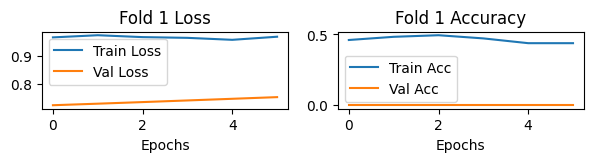

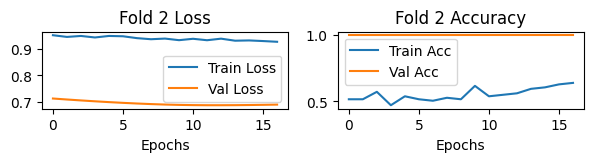

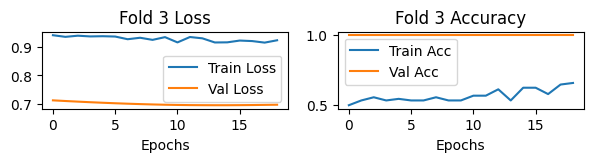

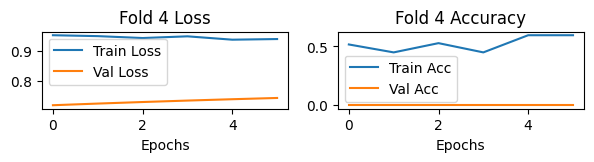

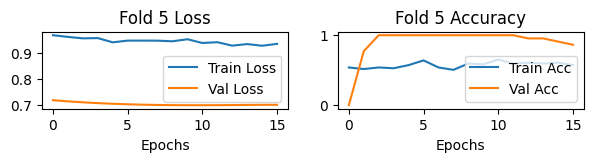

In [36]:
for i, history in enumerate(histories, 1):
    plt.figure(figsize=(7,1))

    # Loss
    plt.subplot(1,2,1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Fold {i} Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Accuracy
    plt.subplot(1,2,2)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f'Fold {i} Accuracy')
    plt.xlabel('Epochs')
    plt.legend()

    plt.show()

Total Depression Heatmaps collected: 111
Total Anxiety Heatmaps collected: 111


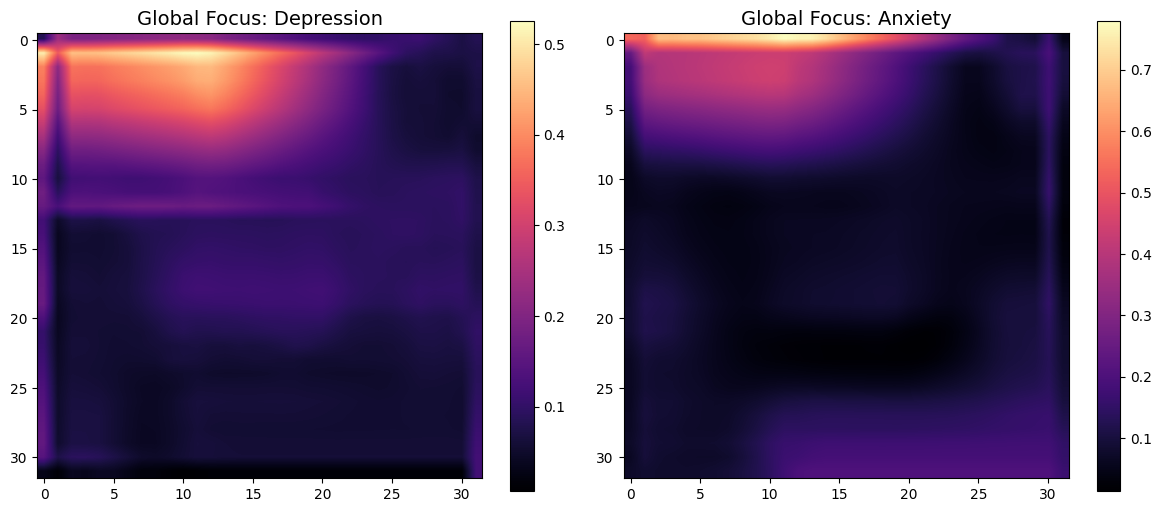

In [156]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Verify list lengths
print(f"Total Depression Heatmaps collected: {len(global_heatmaps_dep)}")
print(f"Total Anxiety Heatmaps collected: {len(global_heatmaps_anx)}")

# 2. Aggregation with a safety check for NaNs
def safe_aggregate(heatmap_list):
    # Stack into a 3D array (N, 64, 64)
    stacked = np.array(heatmap_list)
    # Average across the first axis, ignoring any NaNs just in case
    return np.nanmean(stacked, axis=0)

if len(global_heatmaps_dep) > 0:
    avg_dep = safe_aggregate(global_heatmaps_dep)
    avg_anx = safe_aggregate(global_heatmaps_anx)

    # 3. Final Comparison Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    im1 = axes[0].imshow(avg_dep, cmap='magma', interpolation='bilinear')
    axes[0].set_title("Global Focus: Depression", fontsize=14)
    plt.colorbar(im1, ax=axes[0])
    
    im2 = axes[1].imshow(avg_anx, cmap='magma', interpolation='bilinear')
    axes[1].set_title("Global Focus: Anxiety", fontsize=14)
    plt.colorbar(im2, ax=axes[1])
    
    plt.tight_layout()
    plt.show()
else:
    print("Lists are empty. Ensure 'global_heatmaps_dep.append(hm_dep)' is inside your fold loop.")

In [81]:
# shap_to_plot = (n_samples, n_features)
mean_abs_shap = np.abs(shap_to_plot).mean(axis=0)

shap_importance = pd.Series(mean_abs_shap, index=feature_names_chain)

# Sort descending
shap_importance_sorted = shap_importance.sort_values(ascending=False)

print(shap_importance_sorted.head(15))

rank = shap_importance_sorted.index.get_loc('Depression_Context') + 1
value = shap_importance_sorted['Depression_Context']

print(f"Depression_Context Rank: {rank}")
print(f"Importance Score: {value}")

Depression_Context     0.326234
Lachnoanaerobaculum    0.195265
Raoultella             0.114204
Corynebacterium        0.089415
Lancefieldella         0.087326
Fructilactobacillus    0.028744
Gardnerella            0.006652
Trueperella            0.005872
Veillonella            0.002090
Kocuria                0.001847
Pseudobutyrivibrio     0.000000
Ruthenibacterium       0.000000
Lachnospira            0.000000
Lawsonella             0.000000
dtype: float32
Depression_Context Rank: 1
Importance Score: 0.3262343406677246


In [53]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=1):
    # ensure model is called
    _ = model(img_array)

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.outputs[0]
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)

    max_val = tf.reduce_max(heatmap)
    if max_val != 0:
        heatmap = heatmap / max_val

    return heatmap.numpy()

In [68]:
img = X_img[4]
img_input = np.expand_dims(img, axis=0)

heatmap = make_gradcam_heatmap(
    img_input,
    model,
    last_conv_layer_name='conv2d_9',
    pred_index=1
)


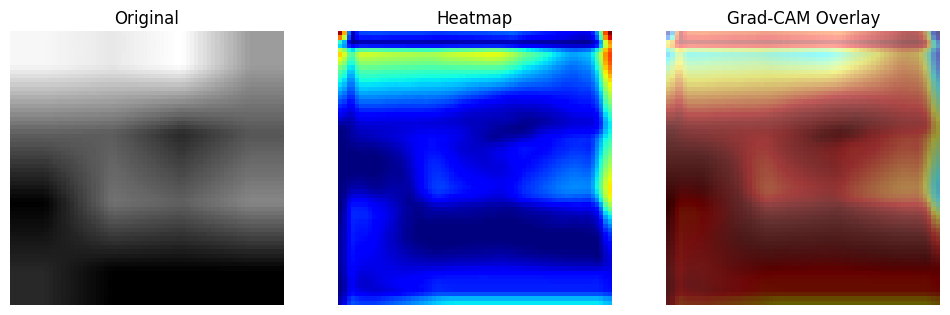

In [69]:
# Resize heatmap to image size
heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

# Convert to RGB if grayscale
if len(img.shape) == 3 and img.shape[-1] == 1:
    img_display = img.squeeze()
else:
    img_display = img

# Create colored heatmap
heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)

# Normalize original image
img_norm = (img_display - img_display.min()) / (img_display.max() - img_display.min())

# Convert grayscale to 3-channel
img_rgb = np.stack([img_norm]*3, axis=-1)

# Overlay heatmap
overlay = 0.6 * img_rgb + 0.4 * (heatmap_color / 255.0)

# Plot
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Original")
plt.imshow(img_display, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title("Heatmap")
plt.imshow(heatmap_resized, cmap='jet')
plt.axis('off')

plt.subplot(1,3,3)
plt.title("Grad-CAM Overlay")
plt.imshow(overlay)
plt.axis('off')

plt.show()